In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [ ]:
def calculate_d1_d2(S, K, T, r, sigma):

    d1 = (np.log(S/K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    return d1,d2

def black_scholes_price(S, K, T, r, sigma):  

    d1, d2 = calculate_d1_d2(S, K, T, r, sigma)

    C = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    P = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

    return C,P

In [ ]:
S0 = 100
sigma = 0.20
r = 0.05
T = 1
K = 100
n = 100
M = 2000000
t_array = np.linspace(0, T, n+1)
rng = np.random.default_rng(4)

delta_t = T/n

In [ ]:
randoms = rng.normal(0, np.sqrt(delta_t), size = (M, n))
zeros = np.array([[0]] * M)

brownian_increments = np.concatenate((zeros, randoms), axis = 1)
brownian = np.cumsum(brownian_increments, axis = 1)

diffusion = np.multiply(sigma, brownian)
drift = np.multiply(t_array, (r - 0.5 * (sigma**2)))

price_factor = np.exp(drift + diffusion)
prices = np.multiply(S0, price_factor)

In [ ]:
tau = 1 - t_array[:-1]
d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
delta = norm.cdf(d1)

option_premium, _ = black_scholes_price(S0, K, T, r, sigma)


delta_change = np.diff(delta, axis = 1)
interest = np.exp(r * tau[1:])

rebalance_costs = delta_change * prices[:, 1:-1]
adjusted_costs = rebalance_costs * interest
total_cost = np.sum(adjusted_costs, axis=1)

initial_cash = option_premium - (prices.T[0] * delta.T[0])
initial_cash *= np.exp(r * T)

terminal_cash = initial_cash - total_cost

portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]

call_payoff = np.maximum(prices.T[-1] - K, 0)

error = portfolio_value - call_payoff

In [65]:

M = 50000000
batch_size = 50000

rng = np.random.default_rng(4)

errors = np.empty(M)

tau = T - t_array[:-1]
interest = np.exp(r * tau[1:])
drift = (r - 0.5 * sigma**2) * t_array

option_premium, _ = black_scholes_price(S0, K, T, r, sigma)

for start in range(0, M, batch_size):

    end = min(start + batch_size, M)
    batch_M = end - start

    randoms = rng.normal(0, np.sqrt(delta_t), size=(batch_M, n))
    zeros = np.zeros((batch_M, 1))

    brownian_increments = np.concatenate((zeros, randoms), axis=1)
    brownian = np.cumsum(brownian_increments, axis=1)

    diffusion = sigma * brownian
    price_factor = np.exp(drift + diffusion)
    prices = S0 * price_factor

    d1, _ = calculate_d1_d2(prices[:, :-1], K, tau, r, sigma)
    delta = norm.cdf(d1)

    delta_change = np.diff(delta, axis=1)

    total_cost = np.einsum(
        "ij,ij,j->i",
        delta_change,
        prices[:, 1:-1],
        interest
    )   
    
    initial_cash = option_premium - S0 * delta[:, 0]
    terminal_cash = initial_cash * np.exp(r * T) - total_cost

    
    portfolio_value = terminal_cash + prices[:, -1] * delta[:, -1]
    call_payoff = np.maximum(prices[:, -1] - K, 0)

    error = portfolio_value - call_payoff

    errors[start:end] = error

print("Mean:", np.mean(errors))
print("Standard deviation:", np.std(errors))
print("RMSE:", np.sqrt(np.mean(errors**2)))


Mean: 8.934724471691956e-05
Standard deviation: 0.4371471589544803
RMSE: 0.4371471680851929


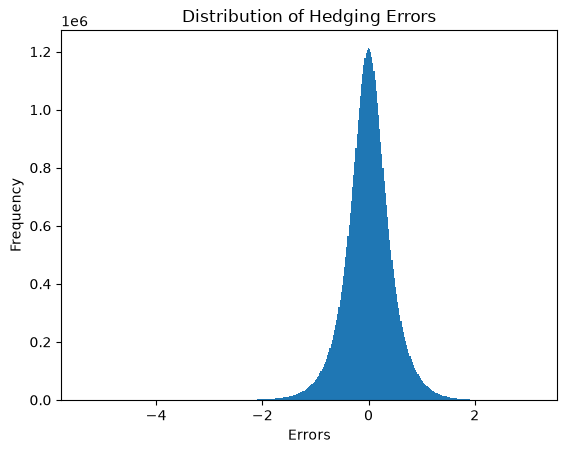

In [66]:
plt.hist(errors,
        bins = 400
         )

plt.xlabel("Errors")
plt.ylabel("Frequency")
plt.title("Distribution of Hedging Errors")

plt.show()